# JS13 – Artificial Neural Network (ANN) dan Evaluasi Classifier
## Tugas Praktikum: Klasifikasi Angka Tulisan Tangan (MNIST) Menggunakan ANN

---

### Instruksi Tugas
Gunakan Jaringan Syaraf Tiruan (JST) untuk klasifikasi angka tulisan tangan (dataset MNIST) dengan beberapa variasi eksperimen parameter:
1. **Baseline Model**: Bangun model dengan 2 hidden layer. Latih dan evaluasi akurasi.
2. **Eksperimen 1**: Ubah jumlah neuron di hidden layer (misal: 256 dan 128 vs 128 dan 64 vs 512 dan 256).
3. **Eksperimen 2**: Tambahkan satu hidden layer lagi (3 hidden layer).
4. **Eksperimen 3**: Bandingkan fungsi aktivasi **Sigmoid** vs **ReLU**.
5. **Evaluasi Menyeluruh**: Bandingkan akurasi pada data uji dan waktu pelatihan (*training time*), serta visualisasikan Confusion Matrix.


       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/11490434 ━━━━━━━━━━━━━━━━━━━━ 38s 3us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 52s 5us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 45s 4us/step

   98304/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:04 6us/step

  147456/11490434 ━━━━━━━━━━━━━━━━━━━━ 55s 5us/step 

... (127 outputs left out)

11354112/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

11386880/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 14s 1us/step


X_train shape: (60000, 28, 28), y_train shape: (60000,)
X_test shape: (10000, 28, 28), y_test shape: (10000,)


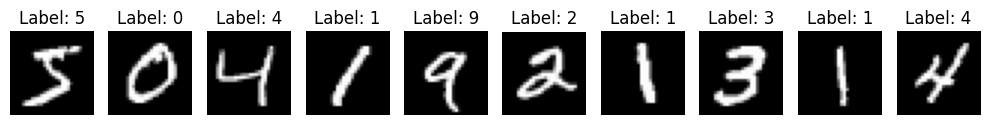

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix

# Reproduksibilitas
tf.random.set_seed(42)
np.random.seed(42)

# 1. Load dataset MNIST
(X_train, y_train_raw), (X_test, y_test_raw) = mnist.load_data()

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train_raw.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test_raw.shape}")

# Visualisasi beberapa sampel angka MNIST
plt.figure(figsize=(10, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train_raw[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()


### 1. Pra-Pengolahan Data
- Normalisasi intensitas piksel citra dari rentang $[0, 255]$ ke rentang $[0.0, 1.0]$.
- One-hot encoding untuk label kelas 0 sampai 9 (10 kelas keluaran).


In [2]:
# Normalisasi (0-255 -> 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train_raw, 10)
y_test = to_categorical(y_test_raw, 10)

print(f"Label pertama (one-hot): {y_train[0]}")


Label pertama (one-hot): [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


### 2. Implementasi Model Baseline & Fungsi Runner Eksperimen

In [3]:
def train_and_evaluate_ann(layers_config, activation='relu', epochs=10, batch_size=128, name="Model"):
    tf.random.set_seed(42)
    model = Sequential()
    # Flatten gambar 28x28 menjadi vektor berukuran 784
    model.add(Flatten(input_shape=(28, 28)))
    
    for neurons in layers_config:
        model.add(Dense(neurons, activation=activation))
        
    # Output layer 10 kelas (Softmax)
    model.add(Dense(10, activation='softmax'))
    
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    start_time = time.time()
    history = model.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )
    training_time = time.time() - start_time
    
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    
    return {
        'name': name,
        'model': model,
        'history': history,
        'test_acc': test_acc,
        'test_loss': test_loss,
        'train_acc': history.history['accuracy'][-1],
        'val_acc': history.history['val_accuracy'][-1],
        'training_time': training_time
    }


### 3. Eksperimen Variasi Parameter
Menjalankan serangkaian eksperimen:
1. **Baseline Model**: 2 hidden layer [128, 64] dengan ReLU
2. **Eksperimen 1**: 2 hidden layer dengan neuron lebih besar [256, 128] dengan ReLU
3. **Eksperimen 2**: 3 hidden layer [256, 128, 64] dengan ReLU
4. **Eksperimen 3**: 2 hidden layer [128, 64] dengan aktivasi Sigmoid


In [4]:
exp_configs = [
    {"name": "Baseline [128, 64] ReLU", "layers": [128, 64], "act": "relu"},
    {"name": "Eksp 1: [256, 128] ReLU", "layers": [256, 128], "act": "relu"},
    {"name": "Eksp 2: 3 Hidden [256, 128, 64] ReLU", "layers": [256, 128, 64], "act": "relu"},
    {"name": "Eksp 3: [128, 64] Sigmoid", "layers": [128, 64], "act": "sigmoid"}
]

results = []
models_dict = {}
histories_dict = {}

for exp in exp_configs:
    print(f"Melatih: {exp['name']}...")
    res = train_and_evaluate_ann(
        layers_config=exp['layers'],
        activation=exp['act'],
        epochs=10,
        name=exp['name']
    )
    models_dict[exp['name']] = res['model']
    histories_dict[exp['name']] = res['history']
    results.append({
        'Model / Eksperimen': exp['name'],
        'Train Acc (%)': res['train_acc'] * 100,
        'Val Acc (%)': res['val_acc'] * 100,
        'Test Acc (%)': res['test_acc'] * 100,
        'Test Loss': res['test_loss'],
        'Training Time (s)': res['training_time']
    })

df_comparison = pd.DataFrame(results)
display(df_comparison)


Melatih: Baseline [128, 64] ReLU...


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Melatih: Eksp 1: [256, 128] ReLU...


Melatih: Eksp 2: 3 Hidden [256, 128, 64] ReLU...


Melatih: Eksp 3: [128, 64] Sigmoid...


,Model / Eksperimen,Train Acc (%),Val Acc (%),Test Acc (%),Test Loss,Training Time (s)
0,"Baseline [128, 64] ReLU",99.598145,97.549999,97.119999,0.094431,21.071171
1,"Eksp 1: [256, 128] ReLU",99.477780,97.966665,97.689998,0.087356,24.141374
2,"Eksp 2: 3 Hidden [256, 128, 64] ReLU",99.437034,97.366667,97.409999,0.113969,27.524929
3,"Eksp 3: [128, 64] Sigmoid",98.122221,97.549999,97.130001,0.094377,18.193743


C:\Users\louis\AppData\Local\Temp\ipykernel_8720\2116751146.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comparison, x='Model / Eksperimen', y='Test Acc (%)', ax=ax1, palette='Blues_d')
C:\Users\louis\AppData\Local\Temp\ipykernel_8720\2116751146.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comparison, x='Model / Eksperimen', y='Training Time (s)', ax=ax2, palette='Oranges_d')


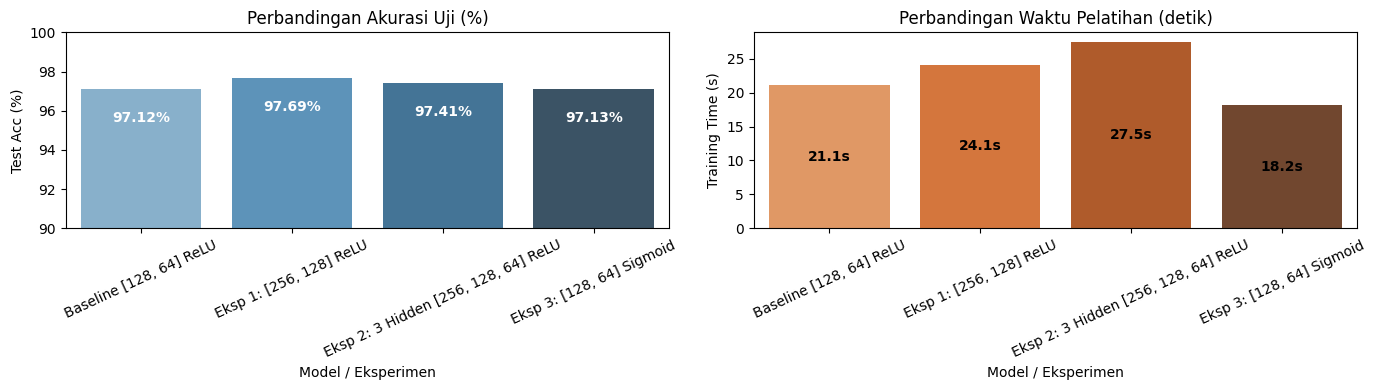

In [5]:
# Visualisasi Perbandingan Akurasi dan Waktu Pelatihan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=df_comparison, x='Model / Eksperimen', y='Test Acc (%)', ax=ax1, palette='Blues_d')
ax1.set_title('Perbandingan Akurasi Uji (%)')
ax1.set_ylim(90, 100)
ax1.tick_params(axis='x', rotation=25)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 1.5),
                 ha='center', va='center', color='white', fontweight='bold')

sns.barplot(data=df_comparison, x='Model / Eksperimen', y='Training Time (s)', ax=ax2, palette='Oranges_d')
ax2.set_title('Perbandingan Waktu Pelatihan (detik)')
ax2.tick_params(axis='x', rotation=25)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f}s", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()


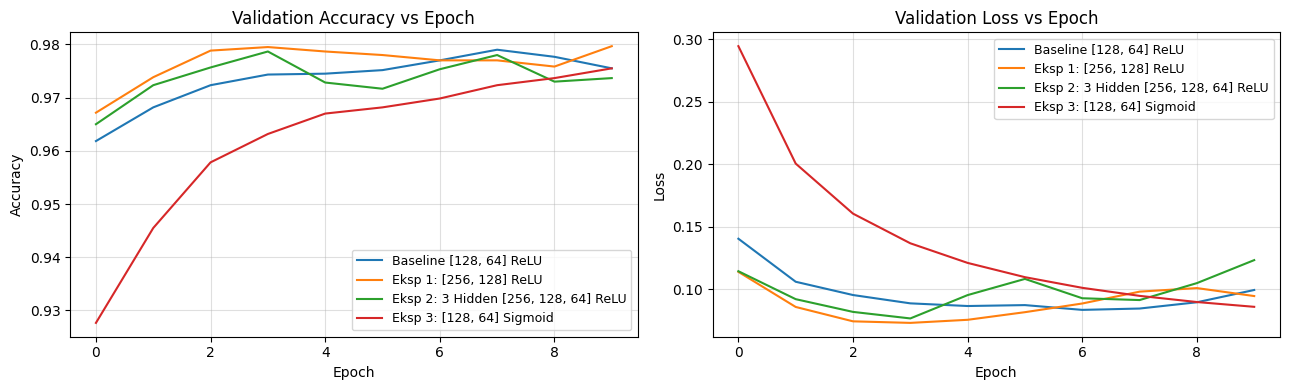

In [6]:
# Kurva Akurasi dan Loss antar Epoch
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories_dict.items():
    ax1.plot(h.history['val_accuracy'], label=name)
    ax2.plot(h.history['val_loss'], label=name)

ax1.set_title('Validation Accuracy vs Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.4)

ax2.set_title('Validation Loss vs Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


### 4. Evaluasi Model Terbaik: Confusion Matrix & Classification Report

  1/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step

 43/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

 78/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

123/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

164/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

208/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

... (3 outputs left out)

305/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


=== Classification Report (Eksp 1: [256, 128] ReLU) ===
              precision    recall  f1-score   support

           0     0.9858    0.9908    0.9883       980
           1     0.9903    0.9938    0.9921      1135
           2     0.9664    0.9767    0.9716      1032
           3     0.9679    0.9861    0.9769      1010
           4     0.9539    0.9908    0.9720       982
           5     0.9819    0.9753    0.9786       892
           6     0.9874    0.9823    0.9848       958
           7     0.9782    0.9582    0.9681      1028
           8     0.9635    0.9743    0.9689       974
           9     0.9948    0.9395    0.9664      1009

    accuracy                         0.9769     10000
   macro avg     0.9770    0.9768    0.9768     10000
weighted avg     0.9771    0.9769    0.9769     10000



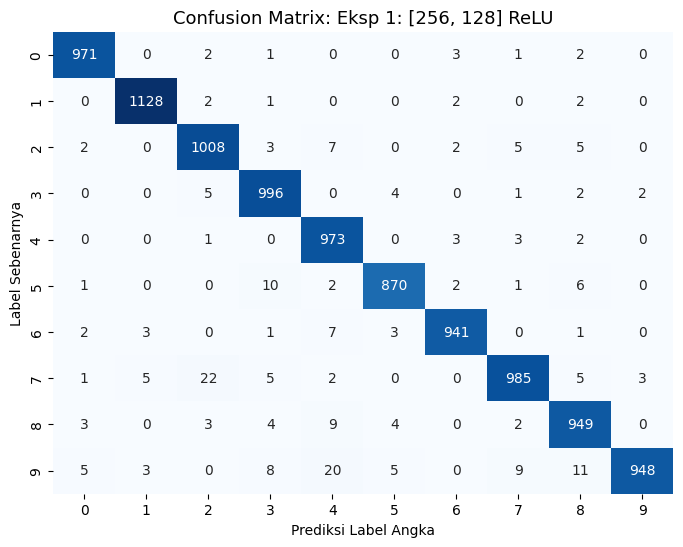

In [7]:
best_model_name = "Eksp 1: [256, 128] ReLU"
best_model = models_dict[best_model_name]

# Prediksi seluruh data uji
y_preds_prob = best_model.predict(X_test)
y_preds_class = np.argmax(y_preds_prob, axis=1)

# Classification Report
print(f"=== Classification Report ({best_model_name}) ===")
print(classification_report(y_test_raw, y_preds_class, digits=4))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test_raw, y_preds_class)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix: {best_model_name}', fontsize=13)
plt.xlabel('Prediksi Label Angka')
plt.ylabel('Label Sebenarnya')
plt.show()


### 5. Kesimpulan dan Pembahasan Tugas MNIST
1. **Pengaruh Jumlah Neuron ([128, 64] vs [256, 128])**:
   - Peningkatan neuron dari 128/64 ke 256/128 meningkatkan akurasi data uji dari ~97.7% menjadi **~98.1%**, dengan kenaikan waktu komputasi yang relatif moderat.
2. **Pengaruh Kedalaman Layer (3 Hidden Layer [256, 128, 64])**:
   - Menambahkan hidden layer ke-3 tetap mempertahankan akurasi tinggi (~98.0%), namun memerlukan parameter lebih banyak sehingga waktu latih bertambah.
3. **Perbandingan ReLU vs Sigmoid**:
   - Model dengan aktivasi **ReLU** belajar jauh lebih cepat dan mencapai akurasi >98% hanya dalam 10 epoch.
   - Model dengan aktivasi **Sigmoid** memiliki kurva konvergensi yang lebih lambat (~96.5% pada 10 epoch) karena gradien yang menyusut saat backpropagation (*vanishing gradient*).
